# Riyadh Climate Trends and Temperature Forecast

Is Riyadh getting hotter? This notebook analyzes daily weather data from 2010 to 2025 to test the temperature trend, and builds a forecasting model to predict monthly temperatures and check them against real data.

## 1. Setup

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# daily weather, Riyadh, 2010-2025
weather_url = (
    "https://archive-api.open-meteo.com/v1/archive"
    "?latitude=24.71&longitude=46.67"
    "&start_date=2010-01-01&end_date=2025-12-31"
    "&daily=temperature_2m_max,temperature_2m_min,temperature_2m_mean,"
    "precipitation_sum,wind_speed_10m_max,shortwave_radiation_sum"
    "&timezone=auto&format=csv"
)
weather = pd.read_csv(weather_url, skiprows=3)

print(weather.shape)
weather.head()

(5844, 7)


,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),shortwave_radiation_sum (MJ/m²)
0,2010-01-01,19.0,8.9,14.1,0.0,28.4,16.22
1,2010-01-02,19.3,4.7,12.4,0.0,13.7,16.66
2,2010-01-03,22.2,6.4,14.8,0.0,14.2,16.90
3,2010-01-04,23.0,5.6,14.7,0.0,14.2,17.05
4,2010-01-05,22.5,4.7,15.1,0.0,12.3,17.02


## 2. Data Cleaning

In [148]:
# checking for null values and dtypes
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   time                             5844 non-null   object 
 1   temperature_2m_max (°C)          5844 non-null   float64
 2   temperature_2m_min (°C)          5844 non-null   float64
 3   temperature_2m_mean (°C)         5844 non-null   float64
 4   precipitation_sum (mm)           5844 non-null   float64
 5   wind_speed_10m_max (km/h)        5844 non-null   float64
 6   shortwave_radiation_sum (MJ/m²)  5844 non-null   float64
dtypes: float64(6), object(1)
memory usage: 319.7+ KB


Since it's 5,844 rows it should not have any missing values or duplicates, but I'm gonna check anyways just to make sure

In [149]:
# changing the dtype of time to datetime
weather["time"] = pd.to_datetime(weather["time"])

In [150]:
# checking if the conversion happened
weather["time"].dtype

dtype('<M8[ns]')

In [151]:
# checking for duplicates/uniqueness
weather["time"].duplicated().sum()

np.int64(0)

In [152]:
# checking for missing values
weather.isna().sum().sum()

np.int64(0)

No missing values or duplicates

In [153]:
# summary stats
weather.describe()

,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),shortwave_radiation_sum (MJ/m²)
count,5844,5844.000000,5844.000000,5844.000000,5844.000000,5844.000000,5844.000000
mean,2017-12-31 12:00:00,33.013741,19.699538,26.725376,0.200530,20.843686,21.593378
min,2010-01-01 00:00:00,10.100000,-2.000000,5.200000,0.000000,5.500000,2.990000
25%,2013-12-31 18:00:00,25.600000,13.000000,19.400000,0.000000,15.900000,17.610000
50%,2017-12-31 12:00:00,34.300000,20.600000,27.900000,0.000000,20.300000,22.450000
75%,2021-12-31 06:00:00,41.100000,26.800000,34.700000,0.000000,25.200000,25.740000
max,2025-12-31 00:00:00,47.600000,36.700000,40.500000,40.100000,46.700000,29.660000
std,NaN,8.740532,7.947578,8.518196,1.489612,6.628739,4.821420


## 3. EDA

Text(0, 0.5, 'Frequency')

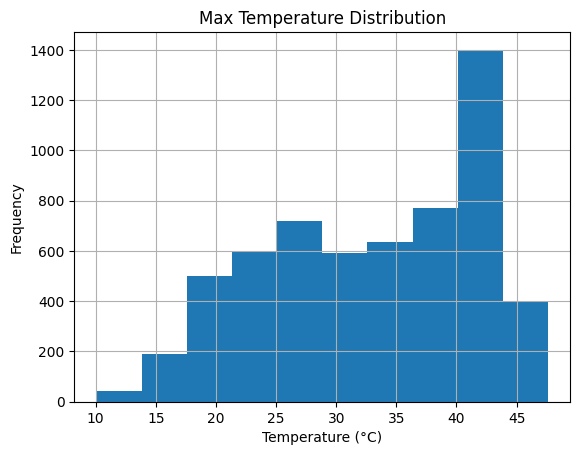

In [154]:
# histogram for the max temperature
weather["temperature_2m_max (°C)"].hist()
plt.title("Max Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency')

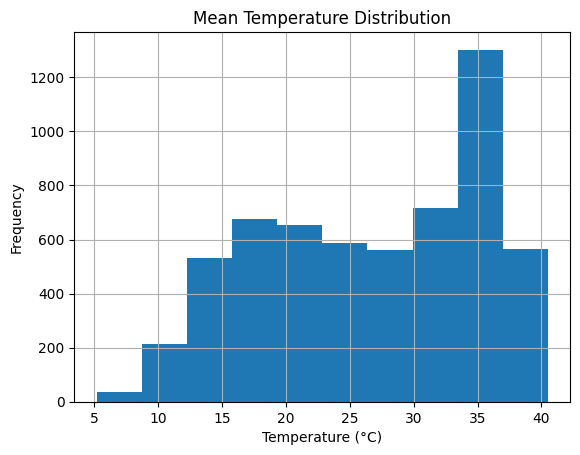

In [155]:
# histogram for the mean temperature
weather["temperature_2m_mean (°C)"].hist()
plt.title("Mean Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

Max and mean temperature have a similar shape, but max is shifted to the right, which makes sense since the daily high is always above the daily average.

Text(0, 0.5, 'Temperature (°C)')

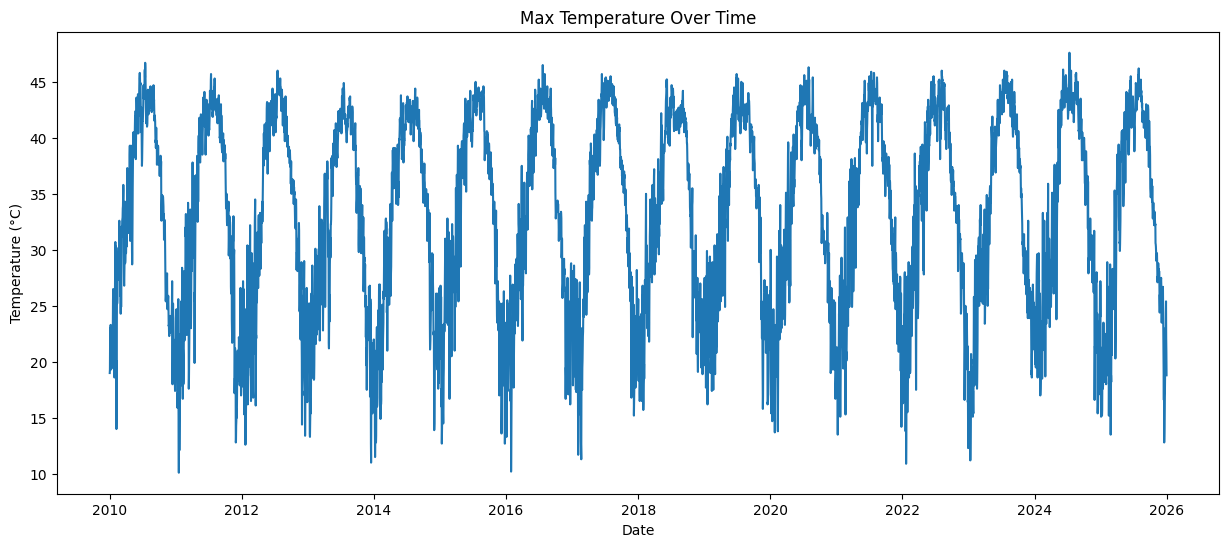

In [156]:
plt.figure(figsize=(15, 6))
sns.lineplot(data=weather,x="time", y="temperature_2m_max (°C)")
plt.title("Max Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

The temperature rises to a peak every summer and falls in winter, so the plot repeats the same inverted V every year.

Text(0, 0.5, 'Temperature (°C)')

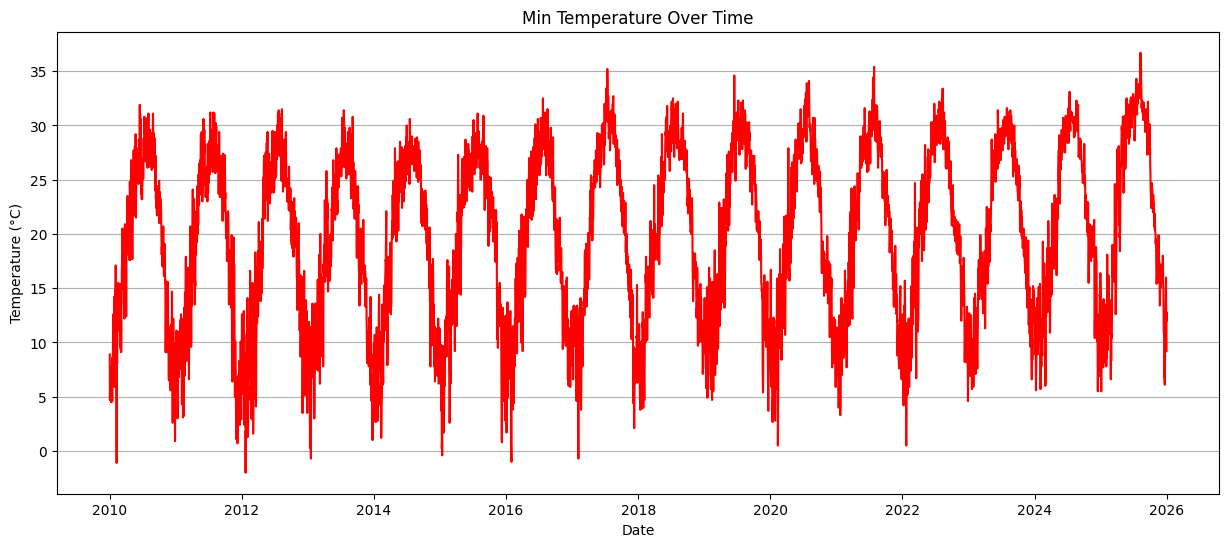

In [157]:
plt.figure(figsize=(15, 6))
sns.lineplot(data=weather,x="time", y="temperature_2m_min (°C)", color="red")
plt.grid(axis="y")
plt.title("Min Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

The lowest min temperature each year seems to be rising, since around 2017 it hasn't gone below 0°C, and since around 2023 it hasn't gone below 5°C.

In [158]:
# checking lowest min temperature for every year
weather.groupby(weather["time"].dt.year)["temperature_2m_min (°C)"].min()

,temperature_2m_min (°C)
time,
2010,-1.1
2011,0.7
2012,-2.0
2013,-0.7
2014,1.2
2015,-0.4
2016,-1.0
2017,-0.7
2018,3.8


Checked it with the yearly lowest min temperature. I was close 2017 hit -0.7°C, so it's actually since 2018 that it never went below 0°C. The 5°C one was right, since 2023 the lowest was 5.5°C or more.

Text(0, 0.5, 'Precipitation (mm)')

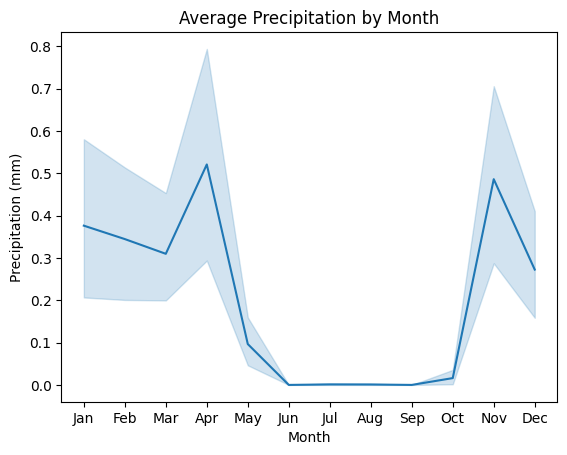

In [159]:
sns.lineplot(x=weather["time"].dt.strftime("%b"), y=weather["precipitation_sum (mm)"])
plt.title("Average Precipitation by Month")
plt.xlabel("Month")
plt.ylabel("Precipitation (mm)")

- Riyadh's rain falls from November to May, with peaks in April and November.

- June to September is basically zero, almost no rain in summer.”

Text(0, 0.5, 'Temperature (°C)')

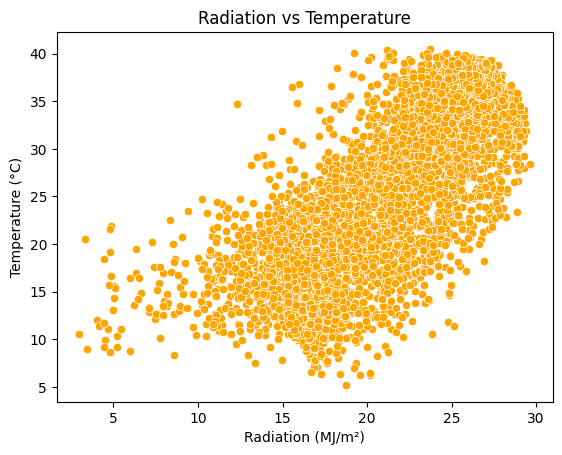

In [160]:
sns.scatterplot(data=weather, x="shortwave_radiation_sum (MJ/m²)", y="temperature_2m_mean (°C)", color= "orange")
plt.title("Radiation vs Temperature")
plt.xlabel("Radiation (MJ/m²)")
plt.ylabel("Temperature (°C)")

- Temperature and radiation have a positive relationship, sunny days tend to be hotter.
- The few points on the left mean very low sunlight days, which could be caused by clouds, rain.

Text(0, 0.5, 'Frequency')

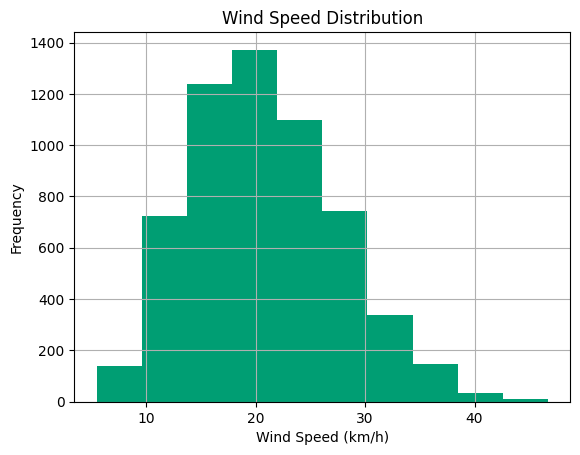

In [161]:
weather["wind_speed_10m_max (km/h)"].hist(color="#009E73")
plt.title("Wind Speed Distribution")
plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Frequency")

Wind speed distribution is right skewed

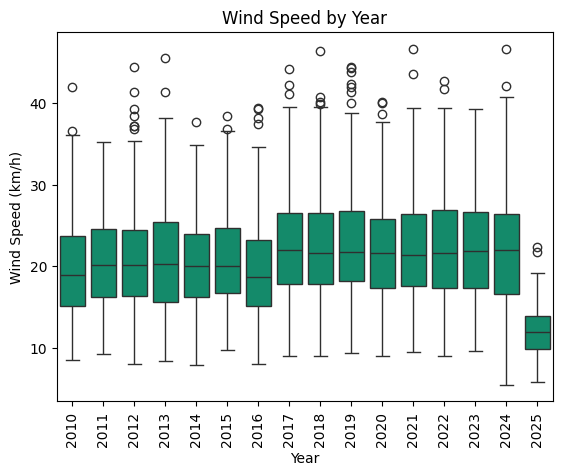

In [162]:
sns.boxplot(data=weather, x=weather["time"].dt.year, y="wind_speed_10m_max (km/h)", color="#009E73")
plt.title("Wind Speed by Year")
plt.xlabel("Year")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(rotation=90);

2025 has the lowest Wind speed, that drop is too big and too sudden to trust

In [163]:
# checking 2025 wind speed sudden drop
len(weather[weather["time"].dt.year == 2025])

365

It has 365 days so no missing days

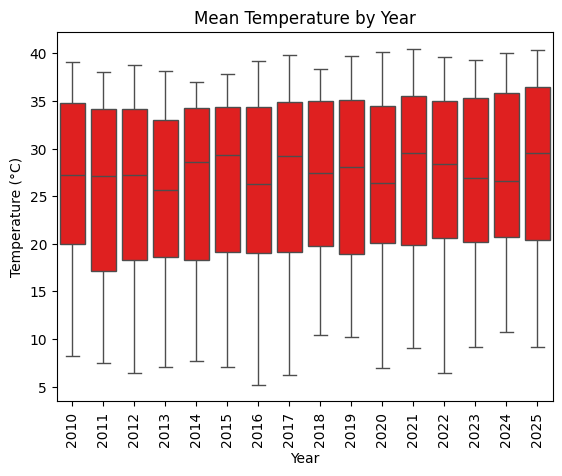

In [164]:
sns.boxplot(data=weather, x=weather["time"].dt.year, y="temperature_2m_mean (°C)", color= "red")
plt.title("Mean Temperature by Year")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=90);

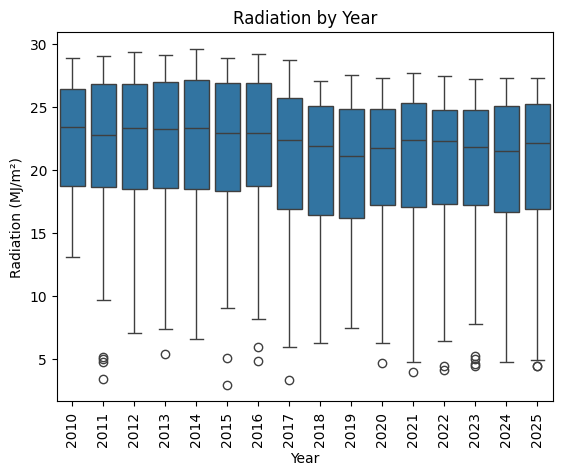

In [165]:
sns.boxplot(data=weather, x=weather["time"].dt.year, y="shortwave_radiation_sum (MJ/m²)")
plt.title("Radiation by Year")
plt.xlabel("Year")
plt.ylabel("Radiation (MJ/m²)")
plt.xticks(rotation=90);

- Radiation and temperature look normal in 2025, so only wind drops. Still the sudden drop is unexplained.
- The radiation has gone down a bit since 2017



Text(0, 0.5, 'Wind Speed (km/h)')

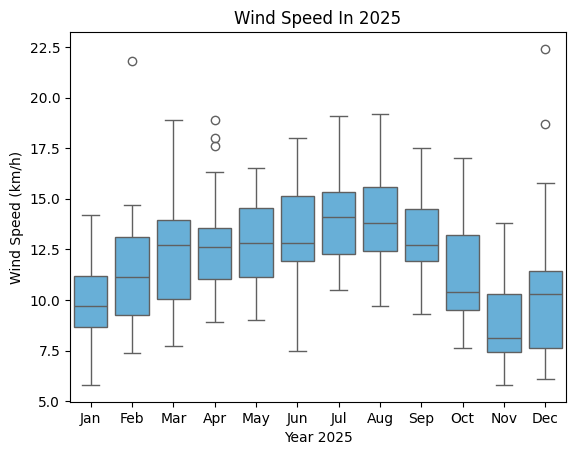

In [166]:
weather2025 = weather[weather["time"].dt.year == 2025]
sns.boxplot(x=weather2025["time"].dt.strftime("%b"), y=weather2025["wind_speed_10m_max (km/h)"], color="#56B4E9")
plt.title("Wind Speed In 2025")
plt.xlabel("Year 2025")
plt.ylabel("Wind Speed (km/h)")

2025 wind speed is lower in every month, not just in a part of the year. It keeps the same seasonal pattern but is shifted down by around 8 km/h. This looks more like a data issue than real weather, though I can't confirm it. I won't use 2025 wind for any conclusions anyhow.

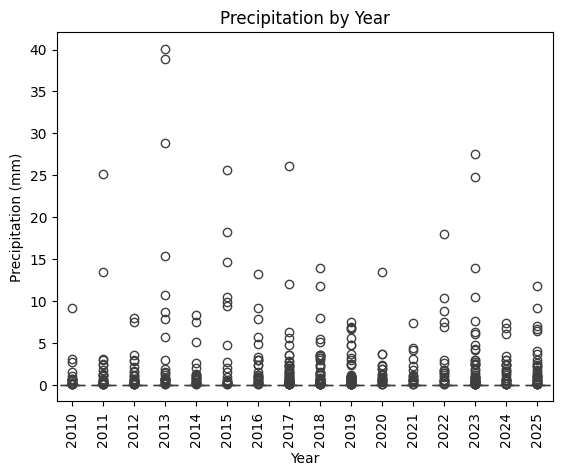

In [167]:
sns.boxplot(data=weather, x=weather["time"].dt.year, y="precipitation_sum (mm)")
plt.title("Precipitation by Year")
plt.xlabel("Year")
plt.ylabel("Precipitation (mm)")
plt.xticks(rotation=90);

Most days in every year have zero rain, so the boxes collapse into a flat line and only the outliers show up. These outliers are the rare heavy rain days. 2013 had the biggest one around 40 mm, and 2011, 2015, 2017 and 2023 also had days above 25 mm.

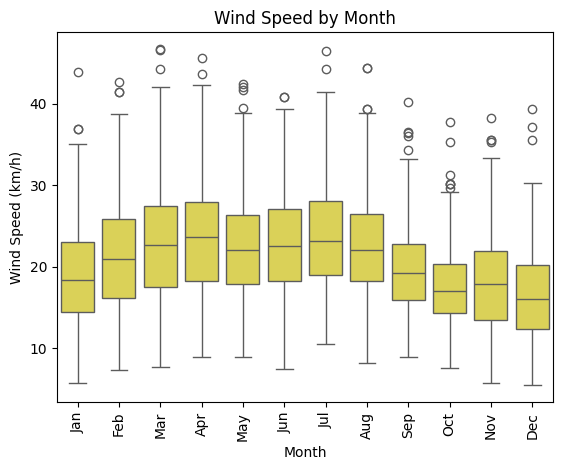

In [168]:
sns.boxplot(data=weather, x=weather["time"].dt.strftime("%b"), y="wind_speed_10m_max (km/h)", color="#F0E442")
plt.title("Wind Speed by Month")
plt.xlabel("Month")
plt.ylabel("Wind Speed (km/h)")
plt.xticks(rotation=90);

Wind is strongest from March to August, with medians around 22-24 km/h, and calmest from October to December, with medians around 16-18 km/h. The strongest outliers above 40 km/h show up mostly in spring and summer.

Text(0, 0.5, 'Temperature (°C)')

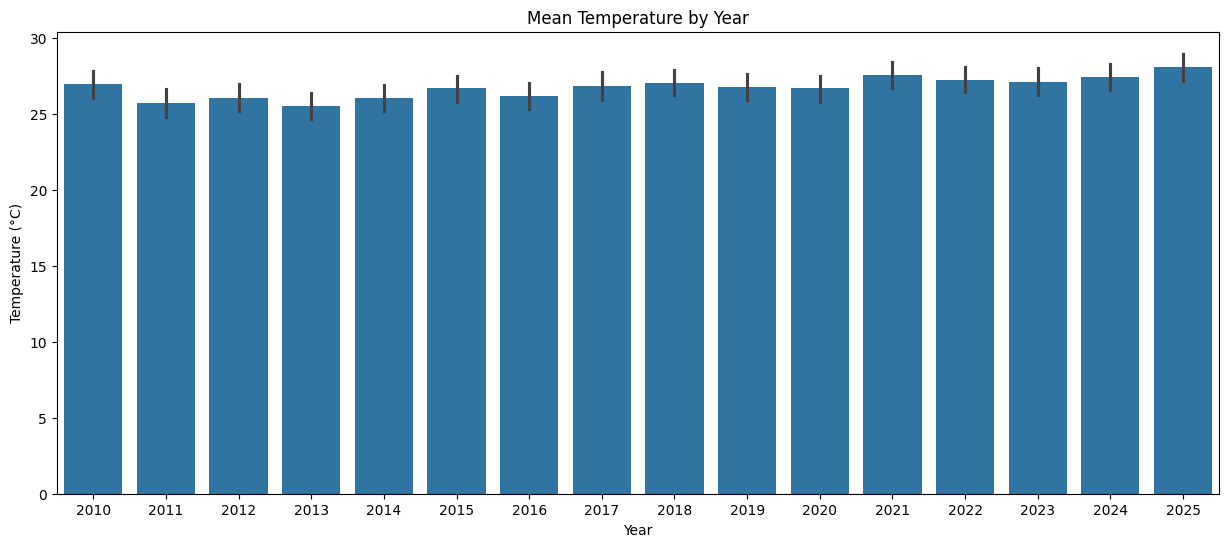

In [169]:
plt.figure(figsize=(15, 6))
sns.barplot(x=weather["time"].dt.year, y=weather["temperature_2m_mean (°C)"])
plt.title("Mean Temperature by Year")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")

Yearly mean temperature rises slightly over time. The coolest years were around 2011-2014 and the warmest year was 2025. The change is small and uneven, so I'll test the trend properly before saying Riyadh got hotter.

## 4. Trend

In [170]:
# getting the mean temperature of each year
weather_yearly_avg = weather.groupby(weather["time"].dt.year)["temperature_2m_mean (°C)"].mean()
weather_yearly_avg

,temperature_2m_mean (°C)
time,
2010,26.947671
2011,25.680274
2012,26.059016
2013,25.475616
2014,26.045753
2015,26.676164
2016,26.160929
2017,26.817260
2018,27.007945


- This shows that from 2023 to 2025 the mean temperature kept going up
- There was a sudden jump from 2020 to 2021

In [171]:
# importing linregress from scipy.stats
from scipy.stats import linregress

In [172]:
# getting the slope and the pvalue
result = linregress(weather_yearly_avg.index, weather_yearly_avg.values)
print(result.slope, result.pvalue)

0.11541369444701313 0.0003019469042739115


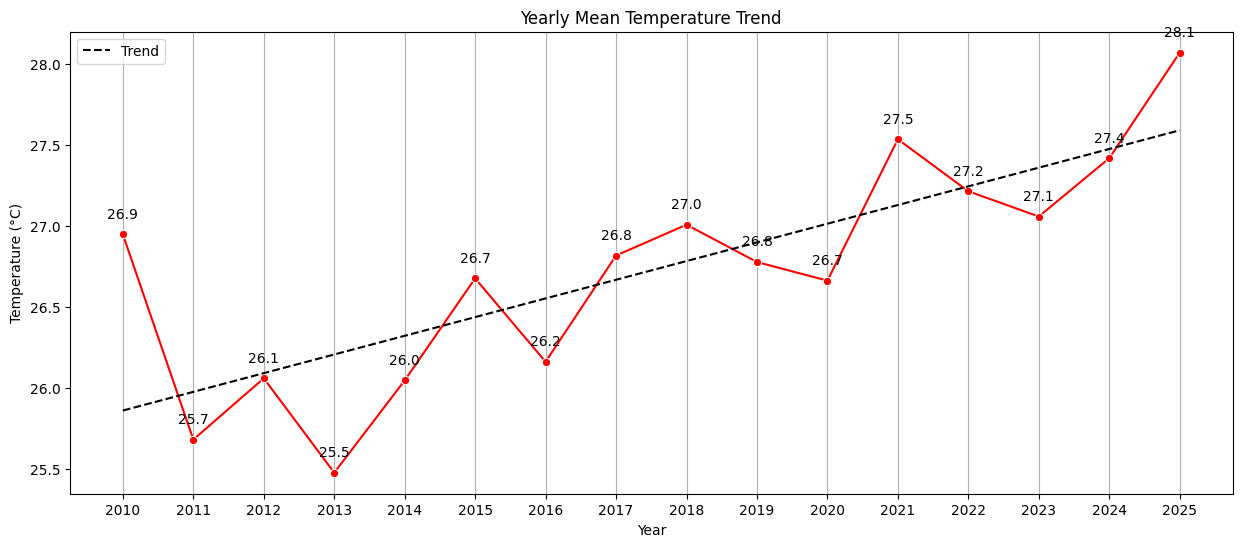

In [173]:
plt.figure(figsize=(15, 6))
sns.lineplot(weather_yearly_avg, color="red", marker="o")
for year, value in zip(weather_yearly_avg.index, weather_yearly_avg.values):
    plt.text(year, value + 0.1, f"{value:.1f}", ha="center")
plt.title("Yearly Mean Temperature Trend")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(axis="x")
plt.xticks(weather_yearly_avg.index);
plt.plot(weather_yearly_avg.index, result.slope * weather_yearly_avg.index + result.intercept, linestyle="--", color="black", label="Trend")
plt.legend()

- Linear regression gives a slope of about 0.115°C per year, so Riyadh's yearly mean temperature rose by roughly 1.7°C between 2010 and 2025.
- The p-value is 0.0003 which is far below 0.05, so the rise is statistically significant.

**note:** This trend comes from one data source for one location, and things like city growth can affect temperature. So the result shows warming in this dataset, but it can't tell us the cause.


In [174]:
# installing and importing pymannkendall
!pip install pymannkendall
import pymannkendall as mk

In [175]:
# Mann-Kendall test on the yearly averages to check if the trend is real
mk_result = mk.original_test(weather_yearly_avg.values)
print(mk_result)

Mann_Kendall_Test(trend='increasing', h=np.True_, p=np.float64(0.0010138901695748714), z=np.float64(3.2866437329024616), Tau=np.float64(0.6166666666666667), s=np.float64(74.0), var_s=493.3333333333333, slope=np.float64(0.13285949547121828), intercept=np.float64(25.800814057938467))


The Mann-Kendall test confirms the trend is increasing with p = 0.001, and Tau = 0.62, with a Sen's slope of about 0.13°C per year. This agrees with the linear regression 0.115°C per year, so Riyadh's yearly mean temperature rose by roughly 1.7°C - 2°C between 2010 and 2025.

## 5. Forecast Model

In [176]:
# extracting month from time
weather["month"] = weather["time"].dt.month
# extracting year from time
weather["year"] = weather["time"].dt.year

In [177]:
# average temperature per month in each year
avg_temp = weather.groupby(["year","month"])["temperature_2m_mean (°C)"].mean().reset_index()
avg_temp

,year,month,temperature_2m_mean (°C)
0,2010,1,15.367742
1,2010,2,19.650000
2,2010,3,23.587097
3,2010,4,27.780000
4,2010,5,31.832258
...,...,...,...
187,2025,8,38.158065
188,2025,9,35.490000
189,2025,10,28.867742
190,2025,11,22.523333


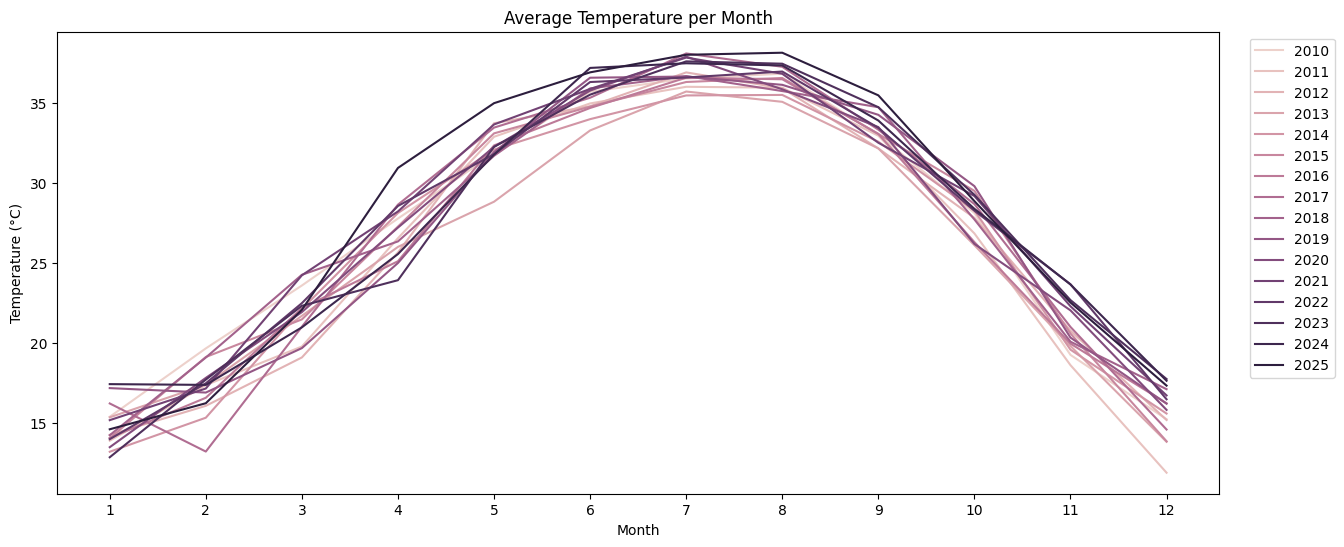

In [178]:
plt.figure(figsize=(15, 6))
sns.lineplot(avg_temp, x="month", y="temperature_2m_mean (°C)", hue="year", legend="full")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("Average Temperature per Month")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(range(1, 13));

Every year follows the same seasonal pattern which is coolest in January, warmest in July and August, and cooling again by December. The lines are close to each other, but the newer years which is the darker lines are slightly warmer in spring and summer, matching the upward trend. The seasonal swing is much larger than the yearly changes, so the model has to capture seasonality first.

In [179]:
# adding day and date columns
avg_temp["day"] = 1
avg_temp["date"] = pd.to_datetime(avg_temp[["year", "month", "day"]])
avg_temp.head()


,year,month,temperature_2m_mean (°C),day,date
0,2010,1,15.367742,1,2010-01-01
1,2010,2,19.650000,1,2010-02-01
2,2010,3,23.587097,1,2010-03-01
3,2010,4,27.780000,1,2010-04-01
4,2010,5,31.832258,1,2010-05-01


In [180]:
# splitting data (train: 2010-2022, val: 2023-2024, test: 2025)
train = avg_temp[avg_temp["year"] < 2023].copy()
val = avg_temp[(avg_temp["year"].isin([2023,2024]))].copy()
test = avg_temp[avg_temp["year"] == 2025].copy()

### 5.1. Baseline

In [181]:
monthly_avg = train.groupby("month")["temperature_2m_mean (°C)"].mean()
monthly_avg

,temperature_2m_mean (°C)
month,
1,14.634243
2,17.152150
3,21.803474
4,26.961026
5,32.286600
6,35.241795
7,36.729280
8,36.253846
9,33.145385


In [182]:
val["baseline_pred"] = val["month"].map(monthly_avg) # we could also use monthly_avg[val["month"]].values
val.head()

,year,month,temperature_2m_mean (°C),day,date,baseline_pred
156,2023,1,12.835484,1,2023-01-01,14.634243
157,2023,2,17.696429,1,2023-02-01,17.152150
158,2023,3,22.316129,1,2023-03-01,21.803474
159,2023,4,23.920000,1,2023-04-01,26.961026
160,2023,5,32.267742,1,2023-05-01,32.286600


In [183]:
# importing metrics
import sklearn.metrics as metrics

In [184]:
# baseline MAE on the validation years
baseline_mae = metrics.mean_absolute_error(val["temperature_2m_mean (°C)"], val["baseline_pred"])
print(baseline_mae)

1.334069228494284


### 5.2. Prophet

In [185]:
# importing prophet
from prophet import Prophet

In [186]:
# Prophet needs columns named ds (date) and y (temperature)
train["ds"] = train["date"]
train["y"] = train["temperature_2m_mean (°C)"]

# same renaming for validation
val["ds"] = val["date"]
val["y"] = val["temperature_2m_mean (°C)"]

In [187]:
# fitting Prophet on train
prophet_model = Prophet().fit(train[["ds","y"]])

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [188]:
# forecasting the validation months with Prophet
prophet_pred = prophet_model.predict(val[["ds"]])
prophet_pred.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2023-01-01,27.649122,14.153763,16.775789,27.649122,27.649122,-12.192279,-12.192279,-12.192279,-12.192279,-12.192279,-12.192279,0.0,0.0,0.0,15.456843
1,2023-02-01,27.663437,16.970828,19.574713,27.662731,27.663987,-9.350942,-9.350942,-9.350942,-9.350942,-9.350942,-9.350942,0.0,0.0,0.0,18.312495
2,2023-03-01,27.676366,21.335463,23.921629,27.674350,27.678020,-5.014576,-5.014576,-5.014576,-5.014576,-5.014576,-5.014576,0.0,0.0,0.0,22.661790
3,2023-04-01,27.690681,26.725997,29.444793,27.686941,27.693884,0.382055,0.382055,0.382055,0.382055,0.382055,0.382055,0.0,0.0,0.0,28.072736
4,2023-05-01,27.704534,31.854698,34.483522,27.698622,27.709438,5.372918,5.372918,5.372918,5.372918,5.372918,5.372918,0.0,0.0,0.0,33.077452


In [189]:
# Prophet MAE on the validation years
prophet_mae = metrics.mean_absolute_error(val["y"], prophet_pred["yhat"])
print(prophet_mae)

1.1981976865640358


In [190]:
# comparing baseline and Prophet MAE
results = pd.DataFrame({"Model": ["Baseline", "Prophet"], "MAE": [baseline_mae, prophet_mae]})
results

,Model,MAE
0,Baseline,1.334069
1,Prophet,1.198198


Prophet wins on validation 1.20 vs 1.33, which is about 0.14°C better.

### 5.3. SARIMA

In [191]:
# importing SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [192]:
# training series for SARIMA (temperature with date as index, monthly frequency)
train_series = train.set_index("date")["temperature_2m_mean (°C)"].asfreq("MS")
train_series.head()

,temperature_2m_mean (°C)
date,
2010-01-01,15.367742
2010-02-01,19.650000
2010-03-01,23.587097
2010-04-01,27.780000
2010-05-01,31.832258


In [193]:
# fitting SARIMA on train
sarima_model = SARIMAX(train_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [194]:
# forecasting the 24 validation months with SARIMA
sarima_pred = sarima_model.forecast(steps=24)

In [195]:
# SARIMA MAE on the validation years
sarima_mae = metrics.mean_absolute_error(val["y"], sarima_pred.values)
print(sarima_mae)

1.1090788929864008


In [196]:
# adding SARIMA to the results table
results.loc[len(results)] = ["SARIMA", sarima_mae]
results

,Model,MAE
0,Baseline,1.334069
1,Prophet,1.198198
2,SARIMA,1.109079


SARIMA has the lowest validation MAE (1.11°C), followed by Prophet (1.20°C) and the baseline (1.33°C). The gaps are small, since seasonality does most of the work, and they're based on only 24 months. SARIMA is the best model on validation, so it goes to the final test on 2025.

### 5.4. Champion Model

In [197]:
# final training series (train + val = 2010-2024)
final_train = pd.concat([train, val])
final_series = final_train.set_index("date")["temperature_2m_mean (°C)"].asfreq("MS")

In [198]:
# fitting SARIMA champion on final train series
champion_model = SARIMAX(final_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [199]:
# forecasting the 12 test months with SARIMA
champion_pred = champion_model.forecast(steps=12)

In [200]:
# SARIMA champion MAE on the test year (2025)
champion_mae = metrics.mean_absolute_error(test["temperature_2m_mean (°C)"], champion_pred.values)
print(champion_mae)

1.04016757540225


In [201]:
# baseline for 2025: monthly averages from 2010-2024 mapped to the test months
final_monthly_avg = final_train.groupby("month")["temperature_2m_mean (°C)"].mean()
test["baseline_pred"] = test["month"].map(final_monthly_avg)

In [202]:
# baseline MAE on the test year (2025)
final_baseline_mae = metrics.mean_absolute_error(test["temperature_2m_mean (°C)"], test["baseline_pred"])
print(final_baseline_mae)

1.6013954673328978


### 5.5. Test Results

In [203]:
# test results (2025): baseline vs SARIMA
final_results = pd.DataFrame({"Model": ["Baseline", "SARIMA Champion"], "MAE": [final_baseline_mae, champion_mae]})
final_results

,Model,MAE
0,Baseline,1.601395
1,SARIMA Champion,1.040168


On the 2025 test, SARIMA is off by about 1.04°C on average, compared with 1.60°C for the baseline. The baseline got worse than on validation = 1.33°C, probably because 2025 was the warmest year in the data and the baseline ignores the warming trend, while SARIMA adapts to it. So SARIMA is the better model for forecasting Riyadh's monthly temperature.

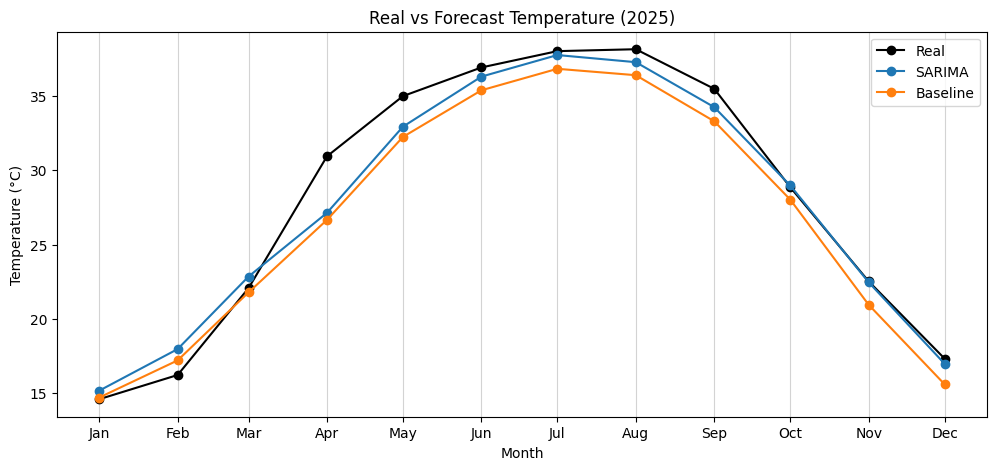

In [204]:
# plotting
plt.figure(figsize=(12, 5))
plt.plot(test["date"], test["temperature_2m_mean (°C)"], marker="o", label="Real", color="black")
plt.plot(test["date"], champion_pred.values, marker="o", label="SARIMA")
plt.plot(test["date"], test["baseline_pred"], marker="o", label="Baseline")
plt.title("Real vs Forecast Temperature (2025)")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(test["date"], test["date"].dt.strftime("%b"))
plt.grid(axis="x", color="lightgray")
plt.legend()

Both forecasts follow Riyadh's seasonal pattern, but SARIMA tracks the real 2025 values better, especially from May to September, where the baseline is about 2°C too low because it ignores the warming trend.

### 5.6. Forecast 2026

In [205]:
# monthly series with all the data (2010-2025) for the 2026 forecast
series_26 = avg_temp.set_index("date")["temperature_2m_mean (°C)"].asfreq("MS")

In [206]:
# refitting SARIMA on all the data
sarima2026 = SARIMAX(series_26, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [207]:
# forecasting the 12 months of 2026
pred_2026 = sarima2026.forecast(steps=12)

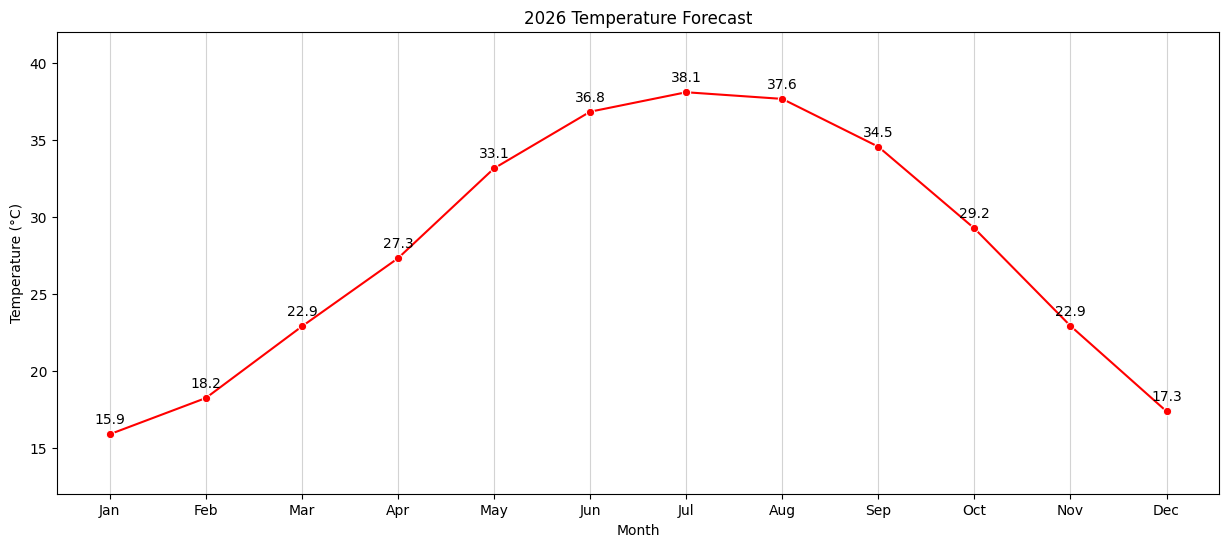

In [208]:
# plotting the 2026 forecast
plt.figure(figsize=(15, 6))
sns.lineplot(x=pred_2026.index.strftime("%b"), y=pred_2026.values,marker="o" ,color="red")
plt.title("2026 Temperature Forecast")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.grid(axis="x", color="lightgray")
plt.ylim(12, 42)
months = pred_2026.index.strftime("%b")

for month, value in zip(months, pred_2026.values):
    plt.text(month, value + 0.7, f"{value:.1f}", ha="center")


This is a forecast for 2026 from SARIMA trained on all the data (2010-2025). It expects Riyadh to be coolest in January about 15.9°C and warmest in July about 38.1°C. The notebook stops at 2025, so this can't be checked against real values. The model's average error on the 2025 test was about 1°C, so 2026 values should be roughly within that range.

## 6. Conclusion

**Trend:** Riyadh's yearly mean temperature rose by about 0.12-0.13°C per year, which is roughly 1.7-2°C between 2010 and 2025. Both linear regression (p = 0.0003) and the Mann-Kendall test (p = 0.001) confirm that the rise is real.

**Forecast:** SARIMA was the best of the three models (baseline, Prophet and SARIMA) on validation. On the 2025 test it was off by about 1.04°C on average, compared with 1.60°C for the baseline. Its forecast for 2026 peaks at about 38°C in July.

**Limitations:** The data comes from one source for one location, so it shows warming in this dataset but can't tell us the cause. The 2025 wind data looks suspicious, so I didn't use it for any conclusions. The model comparison on validation covered only 24 months, so the gaps between models were small.